# Figure 5: personal functional profiles across intestinal sampling regions

CapScan, 347 LC-MS/MS acquisitions from 15 participants: four capsule sampling regions and stool.
Panel a is study-design artwork; panels b-g are regenerated here from `source_data/Fig5/` with the
original drawing code, checked pixel by pixel against the original render, and every Figure 5 statistic
in the Results is recomputed. Run from the repository root with `python paper.py build Fig5`.

Optional inputs: `FASTALAKE_FONT_DIR` (Söhne `.ttf` files, needed for pixel-exact text) and the three
Zenodo files of `source_data/Fig5/README.md` in `build/zenodo/Fig5/` (needed to recompute panels c and d
and the evenness test from acquisition-level profiles). Without them those steps print SKIPPED.

In [1]:
from pathlib import Path
import sys, json
UNIT = Path.cwd()                 # the notebook runs with its own directory as cwd
REPO = UNIT.parents[1]
sys.path[:0] = [str(REPO), str(UNIT)]
SD = REPO / "source_data" / UNIT.name
OUT = REPO / "build" / UNIT.name   # rendered panels; gitignored
OUT.mkdir(parents=True, exist_ok=True)
from style import fl_style as fl   # imported per CONVENTIONS; fl.init() is not called: the Figure 5
import panels                      # producer did not use fl_style, and panels.setup_style() applies its exact settings
import numpy as np, pandas as pd
from IPython.display import Image, display
ZEN = REPO / "build" / "zenodo" / UNIT.name
HAVE_ZENODO = panels.zenodo_ready(ZEN)
print("fonts present:", panels.fonts_available(), "| Zenodo files present:", HAVE_ZENODO)
R = {}                            # every recomputed number, keyed as in panels.NUMBER_KEYS

fonts present: True | Zenodo files present: True


## Panel a

Study design (artwork, `artwork/panel_a.pdf`, the producer's PDF unchanged). Supports "We analyzed 347
existing LC–MS/MS acquisitions from 308 specimens of fifteen healthy participants" (v28d line 147).
n = 347 acquisitions, 308 specimens, 15 participants. No test. The typed counts are compared with the
counts computed from `design_347.tsv`; every typed number is listed in `ARTWORK_NUMBERS.md`.

typed in panel a and recomputed from design_347.tsv: ['347 metaproteomes', '290 capsule · 57 stool', '· 15 participants', '74 acquisitions', '77 acquisitions', '74 acquisitions', '65 acquisitions', '57 acquisitions']
'282 matched acquisitions' typed: True (traced in ARTWORK_NUMBERS.md)


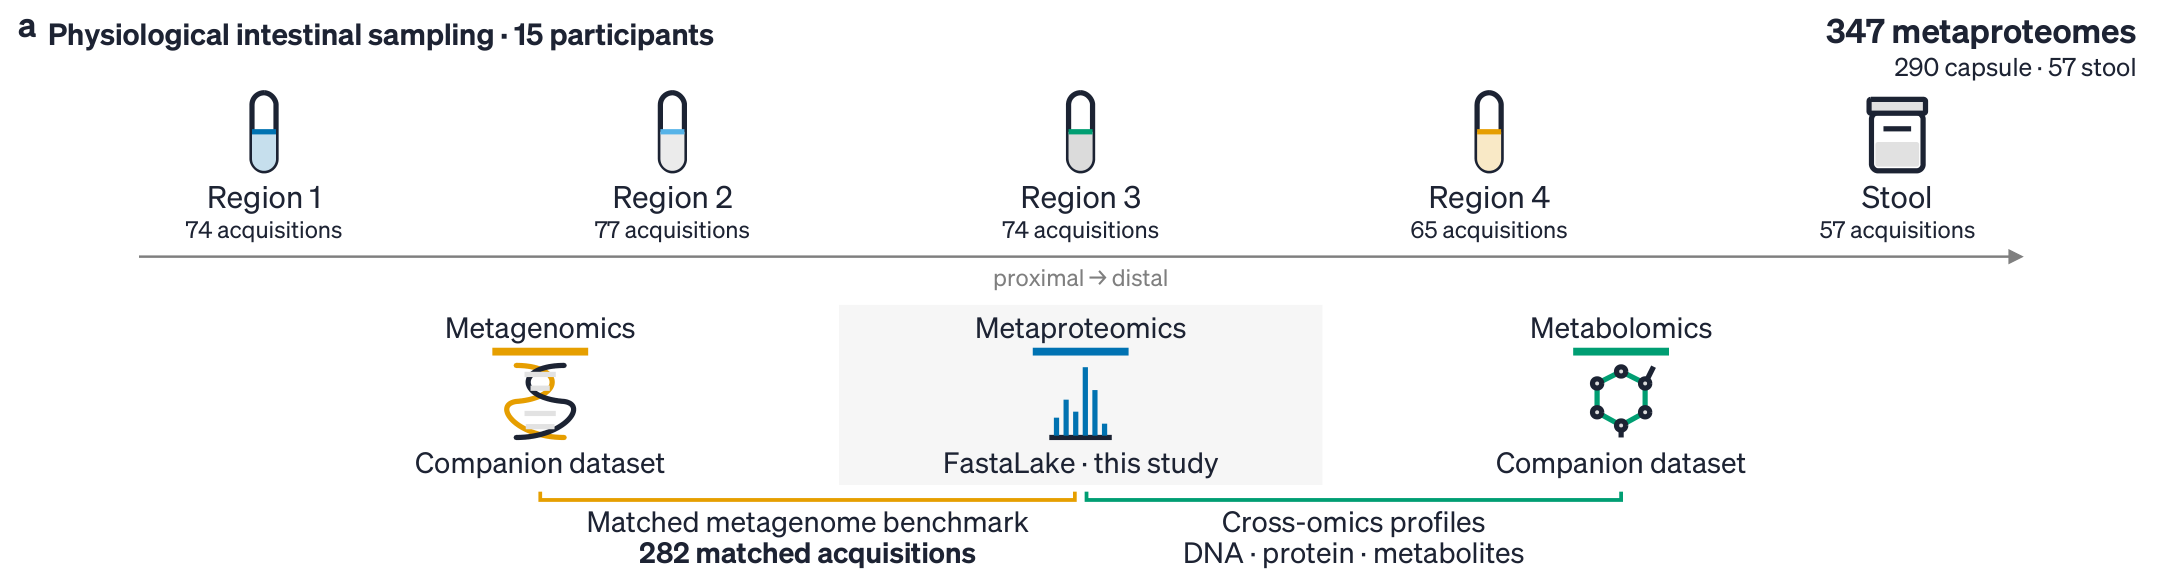

In [2]:
import fitz
A = panels.stat_a_design(SD)
with fitz.open(UNIT / "artwork" / "panel_a.pdf") as doc:
    typed = doc[0].get_text()
    doc[0].get_pixmap(dpi=300, alpha=False).save(OUT / "panel_a.png")
want = [f"{A['acquisitions']} metaproteomes", f"{A['capsule']} capsule · {A['stool']} stool", f"· {A['participants']} participants"]
want += [f"{A['counts'][r]} acquisitions" for r in panels.REG]
missing = [w for w in want if w not in typed]
assert not missing, missing
print("typed in panel a and recomputed from design_347.tsv:", want)
print("'282 matched acquisitions' typed:", "282 matched acquisitions" in typed, "(traced in ARTWORK_NUMBERS.md)")
R.update(L147_acquisitions=A["acquisitions"], L147_specimens=A["specimens"], L147_participants=A["participants"],
         L147_capsule_regions_word=panels.as_word(A["capsule_regions"]))
display(Image(str(OUT / "panel_a.png"), width=700))

## Panel b

Mean human-assigned, microbial and unresolved shares of LFQ intensity per sampling group, with each
participant's human-assigned share. Supports "Regions 1, 2 and 3 had a higher human-assigned share than
stool ... Region 4 exceeded stool by a smaller 4.7 percentage points" (v28d line 149). n = 15
participants (75 participant-region cells from 346 acquisitions). Test: exact two-sided paired sign-flip
(32,768 patterns), percentile-bootstrap 95% CI (2,000 participant resamples), Benjamini-Hochberg over
four regions.

In [3]:
cv = panels.Canvas(SD)
print(panels.panel_b(cv))
cells_new, tests_new = panels.stat_b_region_tests(SD)
cells_ref = pd.read_csv(SD / "origin_fraction_cells.tsv", sep="\t", float_precision="round_trip")
tests_ref = pd.read_csv(SD / "four_region_tests.tsv", sep="\t", float_precision="round_trip")
cols = ["Human-assigned", "Microbial above species", "Microbial species", "Unresolved origin"]
print("cells max |diff|:", panels.compare_tables(cells_new.reset_index(), cells_ref, ["participant", "region"], cols))
print("tests max |diff|:", panels.compare_tables(tests_new, tests_ref, ["region"], ["mean_region", "mean_stool", "mean_difference", "ci_low", "ci_high", "p", "q"]))
print(tests_new.to_string(index=False))
t = tests_new.set_index("region")
R.update(L149_region1_share=t.loc["duodenum", "mean_region"], L149_region4_share=t.loc["colon", "mean_region"],
         L149_stool_share=t.loc["duodenum", "mean_stool"], L149_participants=int(t.n.iloc[0]),
         L149_groups_word=panels.as_word(len(panels.REG)), L153_participants_b=int(t.n.iloc[0]))
for k, reg in zip(["r1", "r2", "r3", "r4"], panels.REG[:4]):
    R[f"L149_diff_{k}"] = t.loc[reg, "mean_difference"]; R[f"L149_ci_lo_{k}"] = t.loc[reg, "ci_low"]
    R[f"L149_ci_hi_{k}"] = t.loc[reg, "ci_high"]; R[f"L149_q_{k}"] = t.loc[reg, "q"]
STATS = {"b": tests_new}
display(cv.fig)

{'q': ['q=0.0028', 'q=0.0028', 'q=0.0028', 'q=0.038'], 'mean_pct': {'Human': [24.96, 23.97, 21.24, 17.52, 12.85], 'Microbial': [52.94, 55.54, 58.72, 64.68, 72.51], 'Unresolved': [22.1, 20.48, 20.04, 17.81, 14.64]}}


cells max |diff|: {'Human-assigned': 0.0, 'Microbial above species': 0.0, 'Microbial species': 0.0, 'Unresolved origin': 0.0}
tests max |diff|: {'mean_region': 0.0, 'mean_stool': 0.0, 'mean_difference': 0.0, 'ci_low': 0.0, 'ci_high': 0.0, 'p': 0.0, 'q': 0.0}
  region  n  mean_region  mean_stool  mean_difference   ci_low   ci_high        p  sum_of_differences  patterns        q
duodenum 15    24.955218   12.846565        12.108653 6.648172 18.663780 0.001038          181.629797     32768 0.002767
 jejunum 15    23.974396   12.846565        11.127831 5.837149 16.435656 0.002075          166.917470     32768 0.002767
   ileum 15    21.239454   12.846565         8.392889 4.523007 12.528244 0.001404          125.893341     32768 0.002767
   colon 15    17.516291   12.846565         4.669727 0.816404  9.106917 0.037964           70.045900     32768 0.037964


<Figure size 720.472x761.505 with 1 Axes>

## Panel c

Mean distance from each participant's four capsule-region functional profiles to their own stool and
to the other fourteen stools. Supports "For each of the fifteen participants, the mean distance ... to
their own stool was smaller ... (mean difference 0.061, 95% CI 0.047–0.075, P≤1 × 10⁻⁵)" (v28d line
155). n = 15 participants, 75 participant-region profiles, 73,316 OGs. Test: two-sided permutation of
stool-to-participant assignments (99,999 permutations); percentile-bootstrap 95% CI (2,000 participant
resamples). The recomputation needs the Zenodo OG profile matrix.

In [4]:
print(panels.panel_c(cv))
if HAVE_ZENODO:
    sim_new, own_new, part_new, roster_ok = panels.stat_cd_profiles(SD, ZEN)
    assert roster_ok, "og_profile_positive in design_347.tsv disagrees with the profile matrix"
    sim_ref = pd.read_csv(SD / "similarity_summary.tsv", sep="\t", float_precision="round_trip"); own_ref = pd.read_csv(SD / "own_stool_participants.tsv", sep="\t", float_precision="round_trip")
    part_ref = pd.read_csv(SD / "orthogonal_partition.tsv", sep="\t", float_precision="round_trip")
    print("similarity max |diff|:", panels.compare_tables(sim_new, sim_ref, ["prevalence"], ["features", "own_closer", "mean_own", "mean_other", "mean_advantage", "ci_low", "ci_high", "p"]))
    print("own-stool max |diff|:", panels.compare_tables(own_new, own_ref, ["prevalence", "participant"], ["own_stool_distance", "other_stool_mean_distance"]))
    print("partition max |diff|:", panels.compare_tables(part_new, part_ref, ["prevalence", "population", "component"], ["fraction"]))
    print(sim_new.to_string(index=False))
    s = sim_new.set_index("prevalence")
    R.update(L153_features=int(s.loc[0.0, "features"]), L155_closer=int(s.loc[0.0, "own_closer"]),
             L155_advantage=s.loc[0.0, "mean_advantage"], L155_ci_lo=s.loc[0.0, "ci_low"], L155_ci_hi=s.loc[0.0, "ci_high"],
             L155_p=s.loc[0.0, "p"], L281_features=int(s.loc[0.0, "features"]), L281_profiles=int(5 * s.loc[0.0, "participants"]),
             L847_profiles=int(5 * s.loc[0.0, "participants"]), L847_features=int(s.loc[0.0, "features"]),
             L847_features_10=int(s.loc[0.1, "features"]), L847_features_20=int(s.loc[0.2, "features"]),
             L847_p_sensitivity=float(max(s.loc[0.1, "p"], s.loc[0.2, "p"])))
    assert (s.own_closer == s.participants).all()
    STATS["c"] = sim_new
else:
    print("SKIPPED: panel c/d recomputation needs the Zenodo files in build/zenodo/Fig5 (see source_data/Fig5/README.md)")
display(cv.fig)

{'n_closer': 15, 'own_mean': 0.4262320527682373, 'other_mean': 0.4869639670550098, 'p': 1e-05, 'features': 73316}


similarity max |diff|: {'features': 0.0, 'own_closer': 0.0, 'mean_own': 0.0, 'mean_other': 0.0, 'mean_advantage': 0.0, 'ci_low': 0.0, 'ci_high': 0.0, 'p': 0.0}
own-stool max |diff|: {'own_stool_distance': 0.0, 'other_stool_mean_distance': 0.0}
partition max |diff|: {'fraction': 0.0}
 prevalence  participants  features  positive_features  own_closer  mean_own  mean_other  mean_advantage   ci_low  ci_high       p  extreme_permutations
        0.0            15     73316              73316          15  0.426232    0.486964        0.060732 0.046566 0.075118 0.00001                     0
        0.1            15     53023              53023          15  0.425947    0.486643        0.060696 0.046520 0.075108 0.00001                     0
        0.2            15     44330              44330          15  0.425514    0.486167        0.060652 0.046494 0.075054 0.00001                     0


<Figure size 720.472x761.505 with 2 Axes>

## Panel d

Share of functional-profile variation explained by participant, the capsule-stool contrast, differences
among capsule regions and residual, with stool (75 profiles) and capsules only (60 profiles). Supports
"participant identity accounted for 45.0% ... In the separate intestinal-fluid-only analysis,
participant identity accounted for 56.9% of variation and sampling region for 5.3%" (v28d line 155).
Descriptive sums-of-squares partition, no test. Recomputed together with panel c.

In [5]:
print(panels.panel_d(cv))
if HAVE_ZENODO:
    pp = part_new[part_new.prevalence.eq(0.0)].set_index(["population", "component"]).fraction * 100
    a5, c4 = "All five regions", "Capsules only"
    R.update(L155_participant=pp[(a5, "Participant")], L155_sampling_group=pp[(a5, "Capsules versus stool")] + pp[(a5, "Between capsule regions")],
             L155_capsule_stool=pp[(a5, "Capsules versus stool")], L155_among_region=pp[(a5, "Between capsule regions")],
             L155_caps_participant=pp[(c4, "Participant")], L155_caps_region=pp[(c4, "Between capsule regions")],
             L849_capsule_stool_exact=pp[(a5, "Capsules versus stool")], L849_among_region_exact=pp[(a5, "Between capsule regions")],
             L849_caps_profiles=int(4 * s.loc[0.0, "participants"]), L849_caps_region_exact=pp[(c4, "Between capsule regions")],
             L849_sampling_group_exact=pp[(a5, "Capsules versus stool")] + pp[(a5, "Between capsule regions")])
    print(pp.round(4).to_string())
else:
    print("SKIPPED: needs the Zenodo files (see panel c)")
display(cv.fig)

['45.0%', '56.9%', '10.7%', '4.2%', '5.3%']
population        component              
All five regions  Participant                44.9902
                  Residual                   40.1729
                  Capsules versus stool      10.6784
                  Between capsule regions     4.1584
Capsules only     Participant                56.8570
                  Residual                   37.8841
                  Capsules versus stool       0.0000
                  Between capsule regions     5.2590


<Figure size 720.472x761.505 with 3 Axes>

## Panel e

Leading annotated species for 24 functions in each participant and sampling group (direct peptide
assignment). Supports "For the 24 displayed functions, the same annotated species led in 50.4% of
individual intestinal-fluid–own-stool comparisons (726 of 1,440) ... 111 of 360 participant–function
combinations (30.8%)" (v28d line 159; Methods line 787). n = 1,440 function-participant-region comparisons
and 360 participant-function profiles. Descriptive counts, no test.

In [6]:
print(panels.panel_e(cv))
mr = pd.read_csv(SD / "mosaic_donor_regions.tsv", sep="\t")
kos = list(pd.read_csv(SD / "mosaic_abundance.tsv", sep="\t").sort_values("row").KO)
E = panels.stat_e_mosaic(mr, kos); print(E)
cov = panels.stat_species_label_coverage(SD); print(cov)
R.update(L153_functions=E["functions"], L157_functions=E["functions"], L159_functions=E["functions"],
         L159_same_leader_pct=100 * E["same_leader_fraction"], L159_same_leader=E["same_leader"], L159_comparisons=E["comparisons"],
         L159_persistence=E["persistence"], L159_persistence_profiles=E["persistence_profiles"],
         L159_persistence_pct=100 * E["persistence_fraction"], L787_persistence_pct=100 * E["persistence_fraction"],
         L159_label_coverage=100 * cov["median_resolved_fraction"])
display(cv.fig)

{'top12': ['B. wexlerae', 'F. saccharivorans', 'P. dorei', 'S. thermophilus', 'E. coli', 'Prevotella sp900557255', 'A. rectalis', 'Ruminococcus sp000437175', 'L. eligens', 'A. soehngenii', 'B. adolescentis', 'A. hallii'], 'persistence': [111, 360], 'same_leader': [726, 1440]}


{'same_leader': 726, 'comparisons': 1440, 'same_leader_fraction': 0.5041666666666667, 'persistence': 111, 'persistence_profiles': 360, 'persistence_fraction': 0.30833333333333335, 'functions': 24}
{'cells': 21168, 'functions': 1467, 'participants': 15, 'median_resolved_fraction': 0.29078817438406557}


<Figure size 720.472x761.505 with 5 Axes>

## Panel f

Per-participant agreement of the leading species between each capsule region and own stool under direct
peptide assignment (production only; the original protein grouping was removed in v30), for all eligible
functions and for the strict subset. Supports "the leading species in an intestinal sampling region matched
that in the participant's own stool in an average of 46.4% of comparisons ... increased agreement to 57.6%"
(v30 Results paragraph 81; v28d line 157 printed 45.6% and 60.0%). n = 15 participants. Descriptive means, no test.


In [7]:
print(panels.panel_f(cv))
F = panels.stat_f_leaders(SD); print(F)
R.update(L157_resolved_direct=100 * F["resolved_direct"], L157_strict_direct=100 * F["strict_direct"],
         L157_participants=F["participants"])
display(cv.fig)


['46.4', '57.6']
{'participants': 15, 'resolved_direct': 0.4642546916329172, 'strict_direct': 0.5756969912129993}


<Figure size 720.472x761.505 with 6 Axes>

## Panel g

Spearman correlations between region-adjusted distance matrices of DNA, non-host protein, host protein
and metabolite profiles (native features, eggNOG OGs, KEGG KOs). Supports "distances between the adjusted
non-host protein profiles correlated with DNA, host protein and metabolite distances (ρ=0.51, 0.55 and
0.38, all q<0.001)" (v28d line 161). n = 13 participants, 65 participant-region profiles. Test: two-sided,
1,999 whole-participant block permutations; Benjamini-Hochberg over 6 native and over 16 functional
comparisons.

In [8]:
print(panels.panel_g(cv))
nat_new = panels.stat_g_native(SD)
nat_ref = pd.read_csv(SD / "native_correlations.tsv", sep="\t", float_precision="round_trip"); nat_ref = nat_ref[nat_ref.analysis.eq(panels.NATIVE_ANALYSIS)]
print("native max |diff|:", panels.compare_tables(nat_new, nat_ref, ["layer_a", "layer_b"], ["rho", "p", "q"]))
fun_new = panels.stat_g_functional(SD)
fun_ref = pd.read_csv(SD / "functional_correlations.tsv", sep="\t", float_precision="round_trip")
fun_ref = fun_ref[fun_ref.scope.eq(panels.FUNCTION_SCOPE) & fun_ref.prevalence.eq(0.0)]
print("functional max |diff|:", panels.compare_tables(fun_new, fun_ref, ["level", "layer_a", "layer_b"], ["rho", "p", "q"]))
print(nat_new[["layer_a", "layer_b", "rho", "p", "q"]].to_string(index=False))
n_ = nat_new.set_index(["layer_a", "layer_b"])
R.update(L153_participants_g=int(nat_new.n_participants.iloc[0]), L161_participants=int(nat_new.n_participants.iloc[0]),
         L161_rho_dna=n_.loc[("DNA", "Non-host protein"), "rho"], L161_rho_host=n_.loc[("Non-host protein", "Host protein"), "rho"],
         L161_rho_met=n_.loc[("Non-host protein", "Metabolites"), "rho"], L161_q_dna=n_.loc[("DNA", "Non-host protein"), "q"],
         L161_q_host=n_.loc[("Non-host protein", "Host protein"), "q"], L161_q_met=n_.loc[("Non-host protein", "Metabolites"), "q"])
STATS.update(g_native=nat_new, g_functional=fun_new)
display(cv.fig)

['0.51*', '0.35*', '0.55*', '0.27*', '0.38*', '0.52*', '0.67*', '0.36*', '0.43*', '0.27*', '0.28*', '0.52*', '0.70*', '0.37*', '0.49*', '0.27*', '0.34*', '—']


native max |diff|: {'rho': 0.0, 'p': 0.0, 'q': 0.0}


functional max |diff|: {'rho': 0.0, 'p': 0.0, 'q': 0.0}
         layer_a          layer_b      rho      p       q
             DNA Non-host protein 0.511864 0.0005 0.00075
             DNA     Host protein 0.348200 0.0020 0.00240
             DNA      Metabolites 0.267710 0.0070 0.00700
Non-host protein     Host protein 0.548168 0.0005 0.00075
Non-host protein      Metabolites 0.382121 0.0005 0.00075
    Host protein      Metabolites 0.523064 0.0005 0.00075


<Figure size 720.472x761.505 with 8 Axes>

## Text statistic: leading-species share and evenness

Not a panel. Supports "The leading species accounted for a median 22.5% of species-resolved signal in
intestinal fluid versus 12.7% in stool, and Pielou evenness was lower (0.623 versus 0.669; 13 of 15
participants in the expected direction for each measure; paired Wilcoxon P=6.1 × 10⁻⁴ and 3.1 × 10⁻⁴)"
(v28d line 159). n = 15 participants (paired). Test: exact two-sided Wilcoxon signed-rank on participant
medians over acquisitions. The per-acquisition metrics are recomputed from the Zenodo species matrix when
present, otherwise read from `evenness_per_acquisition.tsv`.

In [9]:
acq_ref = pd.read_csv(SD / "evenness_per_acquisition.tsv", sep="\t", float_precision="round_trip")
if HAVE_ZENODO:
    acq = panels.stat_evenness_per_acquisition(SD, ZEN)
    print("per-acquisition max |diff|:", panels.compare_tables(acq, acq_ref, ["sample_id"], ["top1", "pielou", "richness", "resolved_mass", "species_resolved_fraction"]))
else:
    print("SKIPPED: per-acquisition recomputation needs function_species.npz; using evenness_per_acquisition.tsv")
    acq = acq_ref
ev, ev_part = panels.stat_evenness(acq)
ref = pd.read_csv(SD / "evenness_summary_tests.tsv", sep="\t", float_precision="round_trip")
print("summary max |diff|:", panels.compare_tables(ev, ref.drop(columns="source"), ["metric"],
      ["participant_median_fluid", "participant_median_stool", "wilcoxon_W", "wilcoxon_p_exact", "signflip_p_exact"]))
print(ev.to_string(index=False))
e = ev.set_index("metric")
assert e.loc["top1", "participants_fluid_gt_stool"] == e.loc["pielou", "participants_fluid_lt_stool"]
R.update(L159_top1_fluid=100 * e.loc["top1", "participant_median_fluid"], L159_top1_stool=100 * e.loc["top1", "participant_median_stool"],
         L159_pielou_fluid=e.loc["pielou", "participant_median_fluid"], L159_pielou_stool=e.loc["pielou", "participant_median_stool"],
         L159_expected_direction=int(e.loc["top1", "participants_fluid_gt_stool"]), L159_paired_n=int(e.loc["top1", "paired_participants"]),
         L159_wilcoxon_top1=e.loc["top1", "wilcoxon_p_exact"], L159_wilcoxon_pielou=e.loc["pielou", "wilcoxon_p_exact"])
STATS["evenness"] = ev

per-acquisition max |diff|: {'top1': 0.0, 'pielou': 2.220446049250313e-16, 'richness': 0.0, 'resolved_mass': 0.0, 'species_resolved_fraction': 0.0}
summary max |diff|: {'participant_median_fluid': 0.0, 'participant_median_stool': 0.0, 'wilcoxon_W': 0.0, 'wilcoxon_p_exact': 0.0, 'signflip_p_exact': 0.0}
metric  acq_n_fluid  acq_n_stool  acq_n_undefined  paired_participants  participant_median_fluid  participant_median_stool  median_paired_difference  mean_paired_difference  participants_fluid_gt_stool  participants_fluid_lt_stool  wilcoxon_W  wilcoxon_p_exact  signflip_p_exact  signflip_patterns
  top1          289           57                1                   15                  0.225222                  0.126504                  0.072457                0.097463                           13                            2         5.0          0.000610          0.000610              32768
pielou          289           57                1                   15                  0.623058    

## Composite

Saves panels b-g as one PDF (the producer's `panels_bg_v30.pdf`), composes it with the panel-a artwork
(the producer's assembly, see `ASSEMBLY.md`), runs the producer's text checks, writes the plotted values
and one crop per panel (`panel_<x>.png`, boxes in `panels.PANEL_BOXES_PT`).

{'png_px': [2162, 2868]} {'font_sizes_pt': [5.0, 5.3, 5.4, 5.5, 5.59, 5.6, 5.7, 6.0, 6.05, 6.1, 6.2, 6.5, 6.9, 6.92, 7.12, 7.2, 7.35, 8.07, 8.13], 'fonts': ['DejaVuSans-Oblique', 'Sohne-Buch', 'Sohne-Halbfett'], 'text_overlaps': []}


inputs read by the panels: {
 "origin_fraction_cells.tsv": "3d73defc53ccab9c2f717638c4dc96365256644d1dcd34dd107290bcffc4a7c6",
 "four_region_tests.tsv": "885df8ef9cef703756cab97240e7662963c3bc6d7dc8f8e555ab842fa90e9736",
 "own_stool_participants.tsv": "67f22f573d418bdee6e7b2a7ed0bc1ccc2fc140ee5793ab10db2455f6002ff0e",
 "similarity_summary.tsv": "ac61627e0eb03c7893603819a7f7b590172cfec50b8d59eb7c30699699f69a39",
 "orthogonal_partition.tsv": "035057c305e7196665b92f91525f4038176d7d41f25a4f4b09cfab51a1921319",
 "mosaic_donor_regions.tsv": "c3b50d0be5b0b4d6256e96c56c675d411db75ae0f9cc9aed62d4dcbbb3404d9e",
 "heatmap_function_key.tsv": "d0ee5641797fd588ba159362019515b340efed901aa03490bd241ea74ff0493c",
 "mosaic_abundance.tsv": "8bf92d581260a971c3aff4824aee008ff7d64d2804789ebbb829dc467a71879f",
 "participant_leaders_resolved.tsv": "0db1bb548130d1d2443ce353dd0657a9c67b5f8664172b7b75f3f0126178d478",
 "participant_leaders_strict_both_methods.tsv": "de2ce4d3935611877671b7414876e31cd9152a31fe3bfc1

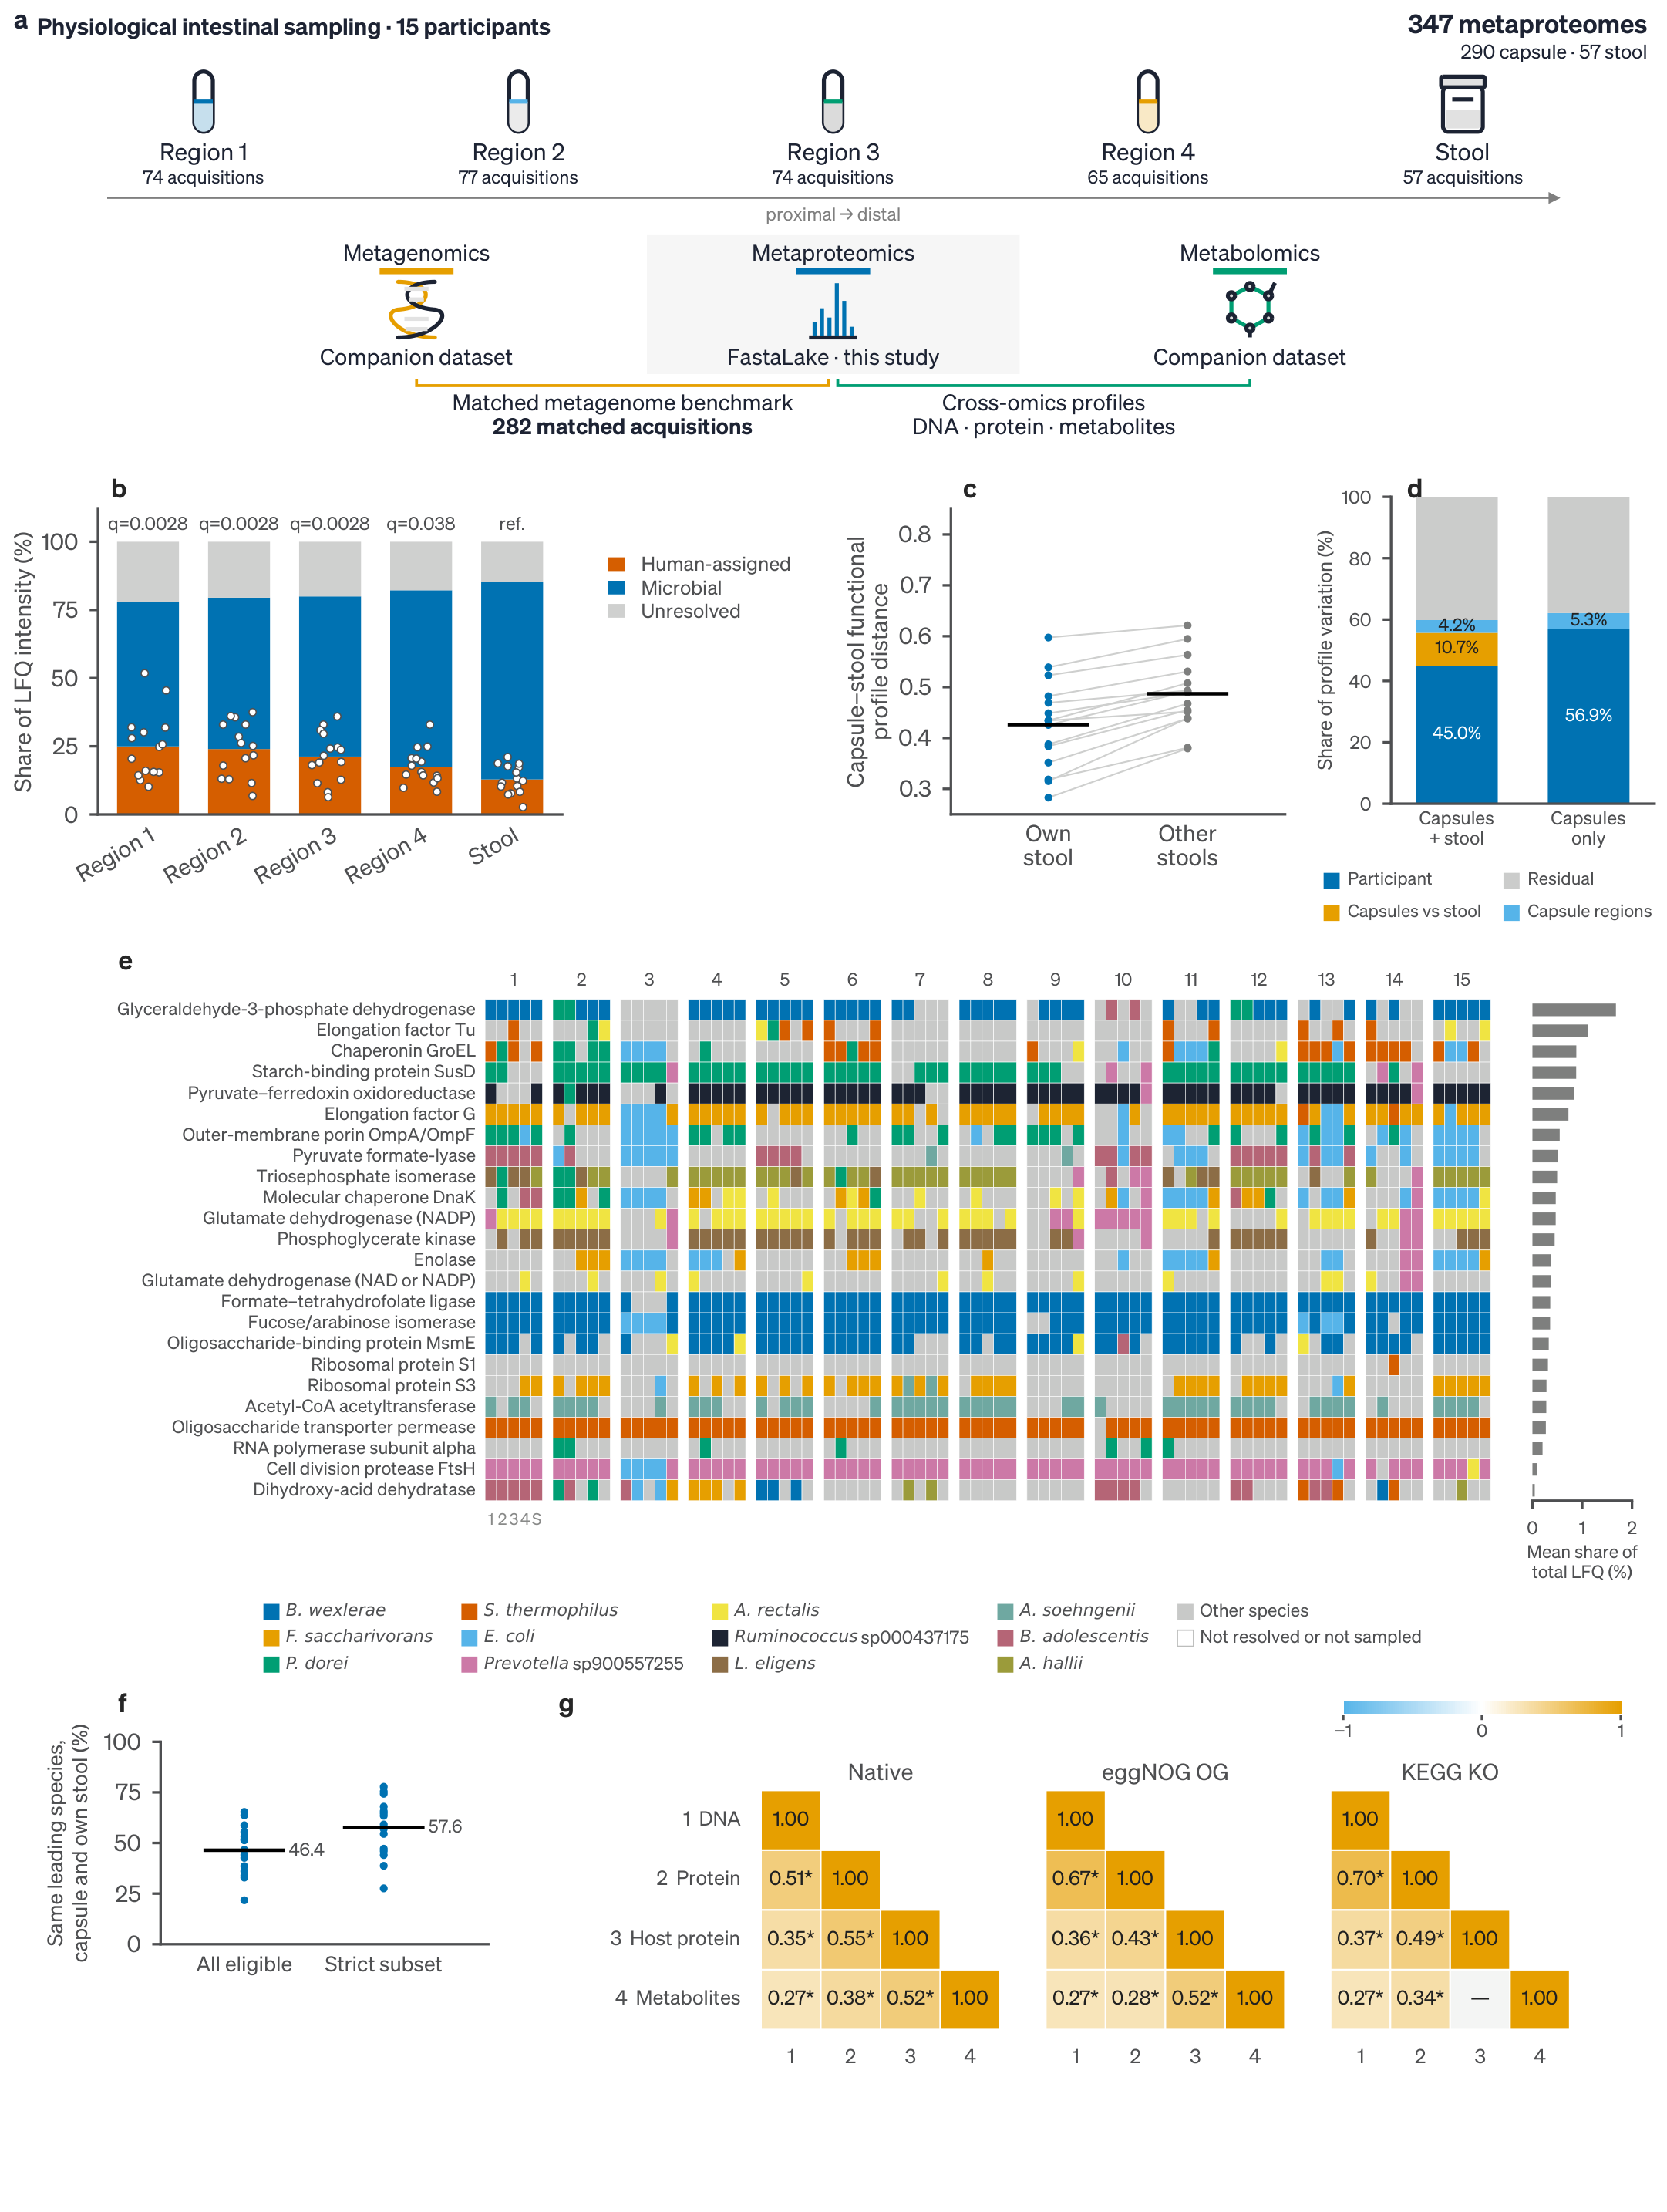

In [10]:
panels.save_body(cv, OUT / "panels_bg.pdf")
info = panels.compose(UNIT / "artwork" / "panel_a.pdf", OUT / "panels_bg.pdf", OUT / "Fig5_v30.pdf", OUT / "Fig5_v30.png")
print(info, panels.check_composite(OUT / "Fig5_v30.pdf"))
panels.plotted_values(cv).to_csv(OUT / "Figure5_plotted_values.tsv", sep="\t", index=False)
crops = panels.crop_panels(OUT / "panels_bg.pdf", OUT)
print("inputs read by the panels:", json.dumps(cv.SRCS, indent=1))
display(Image(str(OUT / "Fig5_v30.png"), width=700))

## Checks

Pixel checks against the original producer's renders (`expected/`), then every recomputed number in
`NUMBERS.tsv` order, compared with the `recomputed_value` column.

In [11]:
import csv
from tools.check_pixels import compare
if panels.fonts_available():
    E_ = UNIT / "expected"
    # the expected per-panel crops must be crops of the producer's own panels-b-g PDF
    tmp = OUT / "expected_crops"; tmp.mkdir(exist_ok=True)
    for k, p in panels.crop_panels(E_ / "panels_bg_v30.pdf", tmp).items():
        assert panels.sha256(p) == panels.sha256(E_ / f"panel_{k}.png"), f"expected/panel_{k}.png is not the producer crop"
    res = {"panels_bg": compare(OUT / "panels_bg.pdf", E_ / "panels_bg_v30.pdf", UNIT / "checks" / "panels_bg", dpi=300)}
    for k in panels.PANEL_BOXES_PT:
        res[k] = compare(OUT / f"panel_{k}.png", E_ / f"panel_{k}.png", UNIT / "checks" / f"panel_{k}", dpi=300)
    res["a_artwork"] = compare(OUT / "panel_a.png", E_ / "panel_a.png", UNIT / "checks" / "panel_a", dpi=300)
    res["composite"] = compare(OUT / "Fig5_v30.png", E_ / "Fig5_v30.png", UNIT / "checks" / "Fig5_v30", dpi=300)
    res["composite_pdf"] = compare(OUT / "Fig5_v30.pdf", E_ / "Fig5_v30.pdf", UNIT / "checks" / "Fig5_v30_pdf", dpi=300)
    for k, r in res.items():
        print(f"{k:14} {r['verdict']:14} differing pixels {r.get('differing_pixels')}")
else:
    print("pixel checks SKIPPED: fonts absent")

rows = list(csv.DictReader(open(UNIT / "NUMBERS.tsv", encoding="utf-8"), delimiter="\t"))
assert len(rows) == len(panels.NUMBER_KEYS), (len(rows), len(panels.NUMBER_KEYS))
bad = []
for key, row in zip(panels.NUMBER_KEYS, rows):
    if key not in R:
        print(f"{row['v28d_line']:>4}  {row['printed_value']:>12}  SKIPPED ({key})"); continue
    val = R[key]; val = val.item() if hasattr(val, "item") else val
    s = repr(val) if isinstance(val, float) else str(val)
    flag = "" if s == row["recomputed_value"] else "  <-- differs from NUMBERS.tsv"
    if flag: bad.append(key)
    print(f"{row['v28d_line']:>4}  {row['printed_value']:>12}  {s}{flag}")
json.dump({k: (v.item() if hasattr(v, "item") else v) for k, v in R.items()}, open(OUT / "recomputed.json", "w"), indent=1)
assert not bad, bad

panels_bg      IDENTICAL      differing pixels 0
b              IDENTICAL      differing pixels 0
c              IDENTICAL      differing pixels 0
d              IDENTICAL      differing pixels 0
e              IDENTICAL      differing pixels 0
f              IDENTICAL      differing pixels 0
g              IDENTICAL      differing pixels 0
a_artwork      IDENTICAL      differing pixels 0
composite      IDENTICAL      differing pixels 0
composite_pdf  IDENTICAL      differing pixels 0
 147           347  347
 147           308  308
 147       fifteen  15
 147          four  four
 149         25.0%  24.95521779116639
 149         17.5%  17.516291284053445
 149         12.8%  12.846564638449962
 149       fifteen  15
 149          five  five
 149          12.1  12.108653152716423
 149          11.1  11.127831352054216
 149           8.4  8.392889372791199
 149           6.6  6.648171633669587
 149          18.7  18.663779807307503
 149           5.8  5.8371493018290455
 149          16.4